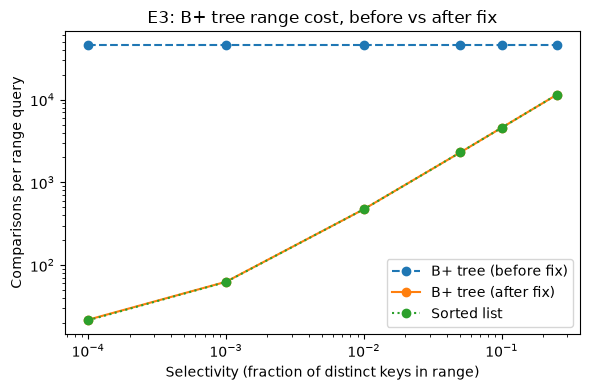

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../results/timings.csv")
BEFORE, AFTER = "f6f773e", "c8ec36c"   # change AFTER if your E3 rerun has a different code_version

e3 = df[(df.experiment.str.startswith("E3")) & (df.rep == 0)].copy()
e3["comp_per_query"] = e3.comparisons / e3.n_ops

fig, ax = plt.subplots(figsize=(6, 4))
lines = [
    ("bplus_tree", BEFORE, "B+ tree (before fix)", "--"),
    ("bplus_tree", AFTER,  "B+ tree (after fix)",  "-"),
    ("sorted_list", AFTER, "Sorted list",          ":"),
]
for index, version, label, style in lines:
    d = e3[(e3.index_type == index) & (e3.code_version == version)].sort_values("operation_param")
    ax.plot(d.operation_param, d.comp_per_query, style, marker="o", label=label)

ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Selectivity (fraction of distinct keys in range)")
ax.set_ylabel("Comparisons per range query")
ax.set_title("E3: B+ tree range cost, before vs after fix")
ax.legend()
fig.tight_layout()
fig.savefig("../incident_reports/INC-01_e3.png", dpi=150)

In [2]:
check = e3[e3.code_version == AFTER].pivot_table(
    index="operation_param", columns="index_type", values="comp_per_query"
)[["bplus_tree", "sorted_list"]]
check

index_type,bplus_tree,sorted_list
operation_param,,
0.0001,21.870,21.545
0.0010,62.875,62.540
0.0100,473.885,473.545
0.0500,2299.885,2299.540
0.1000,4581.845,4581.555
0.2500,11429.805,11429.575
